# Experiment 1 — Exploratory Data Analysis (Iris Dataset)

**Covers:** Dataset information, descriptive statistics, histograms, correlation matrix, heatmap and strongest correlation pairs.

**Dataset:** **Iris** – `Iris.csv` from Kaggle ([uciml/iris](https://www.kaggle.com/datasets/uciml/iris)), 150 flowers, columns `Id, SepalLengthCm, SepalWidthCm, PetalLengthCm, PetalWidthCm, Species`.

**Data file:** keep `Iris.csv` in the **same folder as this notebook** (or replace the file name with its full path, e.g. `pd.read_csv(r"C:\Users\Lab\Desktop\Iris.csv")`).

**Remember:** Load → Describe → Histograms → Correlation → Heatmap → Strongest pairs.

## Import libraries and load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Iris.csv")

## 1. Dataset information

In [2]:
print(df.head())
print(df.shape)
df.info()
print(df.isnull().sum())

   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa
(150, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB
Id         

## 2. Descriptive statistics

In [3]:
num = df[["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]]
print(num.describe())
print(num.agg(["median", "var", "skew", "kurt"]))
print(df["Species"].value_counts())

       SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
count     150.000000    150.000000     150.000000    150.000000
mean        5.843333      3.054000       3.758667      1.198667
std         0.828066      0.433594       1.764420      0.763161
min         4.300000      2.000000       1.000000      0.100000
25%         5.100000      2.800000       1.600000      0.300000
50%         5.800000      3.000000       4.350000      1.300000
75%         6.400000      3.300000       5.100000      1.800000
max         7.900000      4.400000       6.900000      2.500000
        SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
median       5.800000      3.000000       4.350000      1.300000
var          0.685694      0.188004       3.113179      0.582414
skew         0.314911      0.334053      -0.274464     -0.104997
kurt        -0.552064      0.290781      -1.401921     -1.339754
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

## 3. Histograms

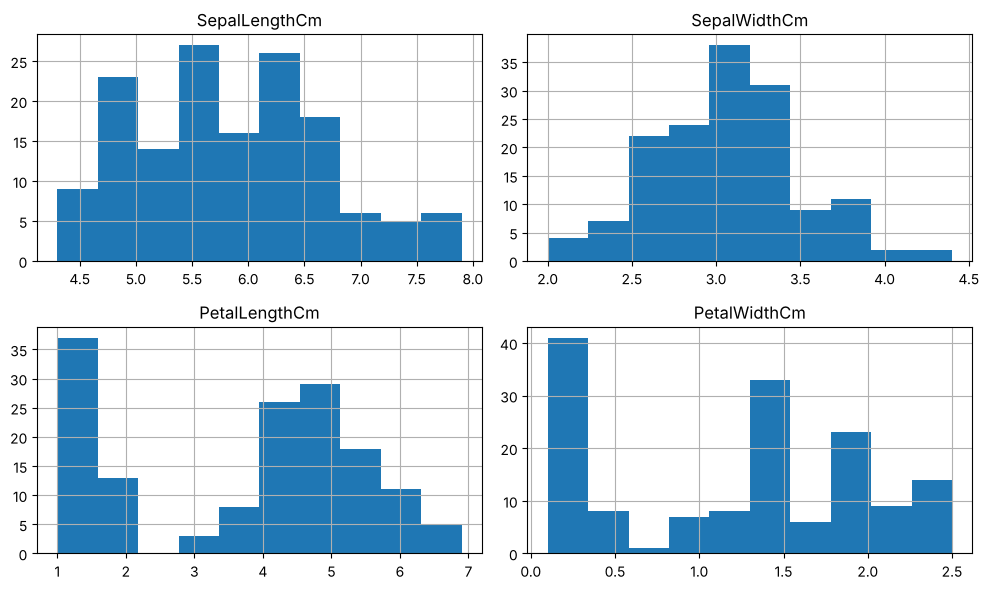

In [4]:
num.hist(bins=10, figsize=(10, 6))
plt.tight_layout()
plt.show()

## 4. Correlation matrix and heatmap

               SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
SepalLengthCm       1.000000     -0.109369       0.871754      0.817954
SepalWidthCm       -0.109369      1.000000      -0.420516     -0.356544
PetalLengthCm       0.871754     -0.420516       1.000000      0.962757
PetalWidthCm        0.817954     -0.356544       0.962757      1.000000


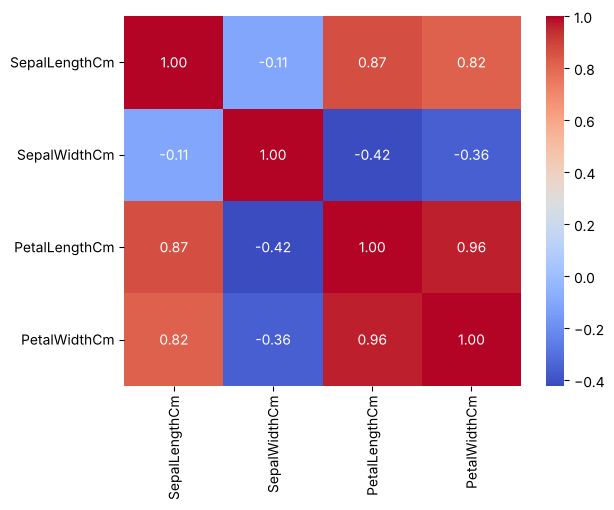

In [5]:
corr = num.corr()
print(corr)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

## 5. Strongest correlations

In [6]:
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
print(pairs.sort_values(key=abs, ascending=False).head(10))

PetalLengthCm  PetalWidthCm     0.962757
SepalLengthCm  PetalLengthCm    0.871754
               PetalWidthCm     0.817954
SepalWidthCm   PetalLengthCm   -0.420516
               PetalWidthCm    -0.356544
SepalLengthCm  SepalWidthCm    -0.109369
dtype: float64


## 6. Pair plot by species

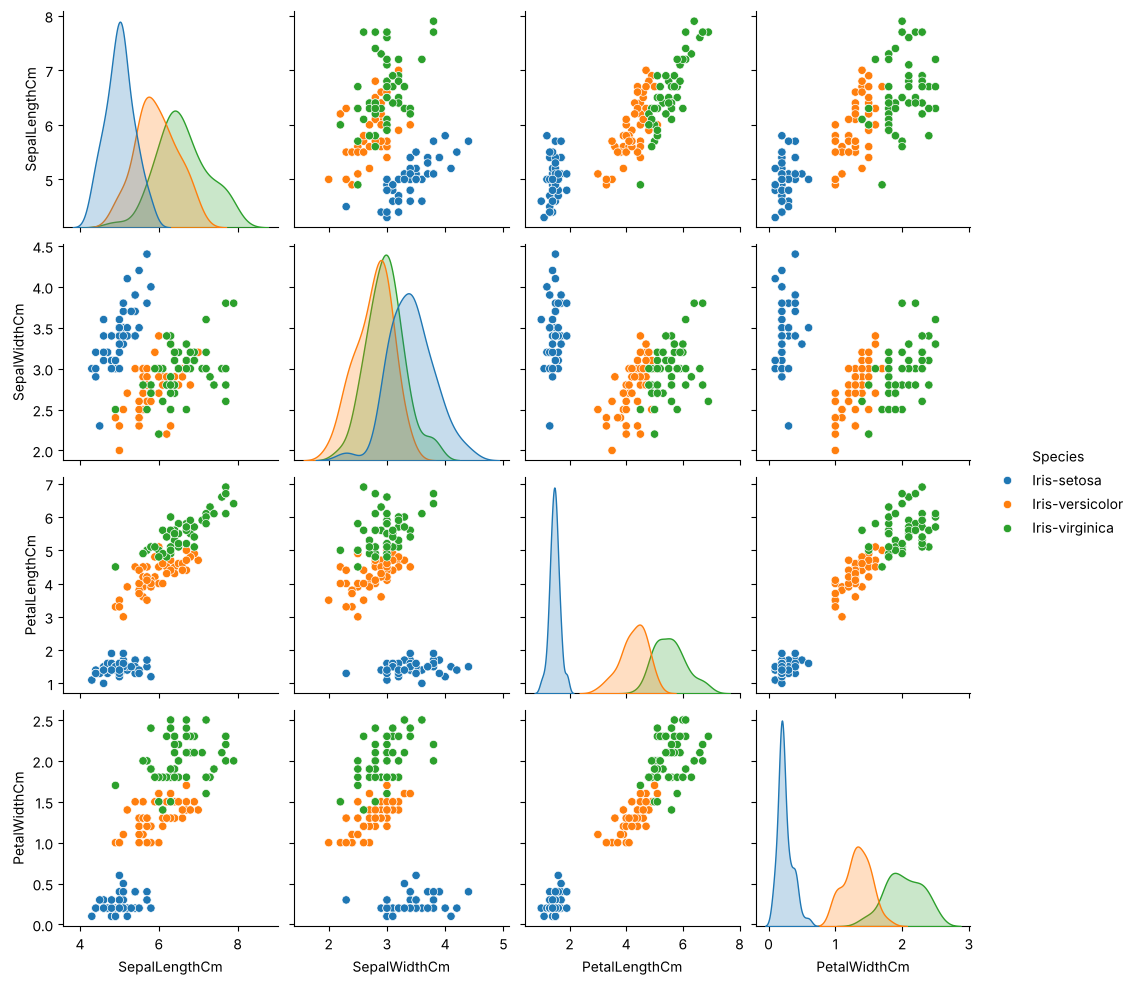

In [7]:
sns.pairplot(df.drop(columns="Id"), hue="Species")
plt.show()

## Result / Conclusion
- 150 rows, 6 columns, **no missing values**, 3 balanced species (50 each).
- Petal measurements vary much more than sepal ones (std 1.76 for `PetalLengthCm` vs 0.43 for `SepalWidthCm`); petal histograms are bimodal because setosa is much smaller.
- Strongest correlation: `PetalLengthCm`–`PetalWidthCm` (r = 0.96), then `SepalLengthCm`–`PetalLengthCm` (r = 0.87). `SepalWidthCm` is weakly negatively correlated with the others.
- The pair plot shows setosa is completely separated; versicolor and virginica overlap a little.